---
title: "Reproduce twelve seasons over Indonesia"
subtitle: "CCA, PCR, raw CFSv2 and climatology · seasons centred on 2023"
execute:
  enabled: false
---

This companion notebook teaches the analysis of forecasts produced through PyCPT.
Reading its already-executed outputs requires only a browser. Running the default
cells uses saved results and scientific Python packages: **no PyCPT installation,
CPT executable, IRI Data Library credentials, data downloads or new fitting** are
required. Use the complete tutorial kit, which includes the data and helper code.

An optional OND section shows the actual PyCPT calibration calls. That extension
requires PyCPT with its compatible CPT engine; it uses local inputs and needs no
IRI Data Library authentication. Outputs go to `temp/`, preserving the research archive.

**Learning goals.** Select target seasons without a year-label error; compare four
forecast methods on identical country-land cells; calculate spatial errors; inspect
geographic differences; distinguish training sensitivity from independent evidence.

## 1. Find the project and check the teaching data

Run from the repository or tutorial-kit folder, or a directory beneath it. The
notebook discovers that root so it also works when Jupyter starts in `docs/notebooks/`.
For default execution, select a kernel with NumPy, pandas, xarray, Matplotlib,
netCDF4 and IPython installed. The kit's `environment/offline-analysis.yml` provides
the scientific-Python package specification; **Python (Tutorial Analysis)** is the
suggested kernel name. An existing working tutorial kernel can also be used.
PyCPT and its CPT executable are needed only if you enable the optional refit.
Hash verification detects changed data before calculating results.

In [1]:
#| label: setup
from pathlib import Path
import sys
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pycpt_tutorial").is_dir() and (p / "docs/data").is_dir()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the full repository or extracted tutorial kit.")
sys.path.insert(0, str(root))
import json
import hashlib
import datetime as dt
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from pycpt_tutorial import teaching as teach
from pycpt_tutorial.export import save_netcdf
%matplotlib inline
teach.style()
data_dir = root / "docs/data"
artifacts = root / "docs/assets/seasonal-2023"
artifacts.mkdir(parents=True, exist_ok=True)
provenance = teach.verify_bundle(data_dir)
def load(name):
    with xr.open_dataset(data_dir / name) as source:
        return source.load()
data = load("indonesia-seasons-2023.nc")
context = load("verification-context-2021-2024.nc")
print(f"Verified {len(provenance['outputs'])} input files; {int(data.evaluation_mask.sum()):,} country-land cells.")

Verified 5 input files; 3,240 country-land cells.


## 2. Keep actual dates visible

A season is a three-month rainfall total, not a single month. This tutorial orders
seasons by their **midpoint in 2023**. DJF spans December 2022–February 2023;
NDJ spans November 2023–January 2024. The research archive uses **ending-year labels**,
so that last window is stored as NDJ **2024**. Keep this source label unchanged.

Each forecast was initialized on the first day of the month before its target begins.
The three CFSv2 lead centres are 1.5, 2.5 and 3.5 months. Monthly rates were integrated
with actual month lengths before this teaching copy was made.

In [2]:
#| label: tbl-calendar
calendar = pd.DataFrame({
    "Season": data.season.values,
    "Initialization": pd.to_datetime(data.initialization.values).strftime("%d %b %Y"),
    "Target starts": pd.to_datetime(data.target_start.values).strftime("%d %b %Y"),
    "Target ends": pd.to_datetime(data.target_end.values).strftime("%d %b %Y"),
    "Research ending year": data.source_season_year.values,
})
assert np.all(pd.DatetimeIndex(data.target_midpoint.values).year == 2023)
assert int(data.source_season_year.sel(season="NDJ")) == 2024
calendar.to_csv(artifacts / "calendar.csv", index=False)
display(HTML(calendar.to_html(index=False, classes="table table-sm", border=0)))

Season,Initialization,Target starts,Target ends,Research ending year
DJF,01 Nov 2022,01 Dec 2022,28 Feb 2023,2023
JFM,01 Dec 2022,01 Jan 2023,31 Mar 2023,2023
FMA,01 Jan 2023,01 Feb 2023,30 Apr 2023,2023
MAM,01 Feb 2023,01 Mar 2023,31 May 2023,2023
AMJ,01 Mar 2023,01 Apr 2023,30 Jun 2023,2023
MJJ,01 Apr 2023,01 May 2023,31 Jul 2023,2023
JJA,01 May 2023,01 Jun 2023,31 Aug 2023,2023
JAS,01 Jun 2023,01 Jul 2023,30 Sep 2023,2023
ASO,01 Jul 2023,01 Aug 2023,31 Oct 2023,2023
SON,01 Aug 2023,01 Sep 2023,30 Nov 2023,2023


## 3. Define a fair comparison

**Observation:** local CHIRPS3 rainfall, aggregated from 0.05° to 0.25° country-land
means. It is a gridded observational estimate, not independent station validation.
**Raw:** the same CFSv2 ensemble-mean seasonal forecast supplied at 1°, interpolated
to the observation grid. A 0.25° output does not establish 0.25° dynamical skill.

**Climatology:** the mean observed total over the fitting period, unchanged from year
to year. **CCA/PCR:** regression-calibrated forecasts, each trained separately for each
target season. The main illustration uses 1991–2020; 1983–2010 is a sensitivity check.
This choice is stated upfront rather than selecting a different winner each season.

The fits retain three predictor EOFs; CCA additionally retains three predictand EOFs
and two CCA modes. Counts are fixed, not optimized. CPT used synchronous predictors
and five-sample cyclic CV, refitting within folds, then fitted the full training period
for the later forecasts. No transform, tailoring, dry mask or skill mask was enabled.
CPT automatically zero-bounds rainfall. These are current-vintage retrospective replays.

In [3]:
#| label: comparison-design
mask = data.evaluation_mask.astype(bool)
weights = data.evaluation_weight.where(mask, 0)
weights = weights / weights.sum(("Y", "X"))
assert int(mask.sum()) == 3240
assert np.isclose(float(weights.sum()), 1)
assert int(data.forecast_rainfall.count()) == 12 * 7 * 3240
assert int(data.observed_rainfall.count()) == 12 * 3240
main_variants = teach.MAIN
print("Same observations, 3,240 cells and normalized country-land weights for every method.")

Same observations, 3,240 cells and normalized country-land weights for every method.


## 4. Calculate errors, rather than ranking maps by appearance

For each seasonal window and forecast, calculate
$e_i=f_i-o_i$, $\mathrm{RMSE}=\sqrt{\sum_i w_i e_i^2}$,
$\mathrm{MAE}=\sum_i w_i|e_i|$, and $\mathrm{bias}=\sum_i w_i e_i$.
The weights sum to one. Positive bias means a forecast is too wet.

These are **spatial scores across Indonesia for one seasonal forecast**, not the
error of a national-mean time series. RMSE penalizes large local errors strongly.
Assertions below independently reproduce the saved scores for every selected window,
including NDJ's different source year.

In [4]:
#| label: tbl-main-scores
error = data.forecast_rainfall - data.observed_rainfall
scores = xr.Dataset({
    "rmse": np.sqrt((error ** 2 * weights).sum(("Y", "X"))),
    "mae": (abs(error) * weights).sum(("Y", "X")),
    "bias": (error * weights).sum(("Y", "X")),
})
for variable in scores:
    scores[variable].attrs["units"] = "mm"
    for season in teach.SEASONS:
        archived = context[variable].sel(season=season,
            season_year=int(data.source_season_year.sel(season=season)))
        np.testing.assert_allclose(scores[variable].sel(season=season), archived, atol=1e-8, rtol=0)
scores = scores.assign_coords(target_start=data.target_start, target_end=data.target_end,
                             initialization=data.initialization, source_season_year=data.source_season_year)
save_netcdf(scores, artifacts / "verification-2023.nc", overwrite=True,
    metadata={"calendar": "Midpoint year2023; source NDJ ending-year2024", "comparison": "Deterministic spatial scores; no probability-skill inference"})
scores.to_dataframe().reset_index().to_csv(artifacts / "metrics-2023.csv", index=False)
rmse = scores.rmse.to_pandas().reindex(teach.SEASONS)
main_rmse = rmse[main_variants].rename(columns=teach.LABELS)
display(HTML(main_rmse.round(2).to_html(classes="table table-sm", border=0)))

forecast_variant,Raw CFSv2,Climatology,CCA,PCR
season,,,,
DJF,484.69,163.87,169.33,169.44
JFM,466.25,158.38,155.97,161.14
FMA,413.45,140.80,134.15,142.06
MAM,370.58,145.54,133.99,135.87
AMJ,350.12,157.28,148.81,147.49
MJJ,379.67,142.65,140.64,140.88
JJA,377.82,130.69,177.98,175.59
JAS,324.42,124.70,162.76,161.39
ASO,290.15,192.06,111.54,112.43


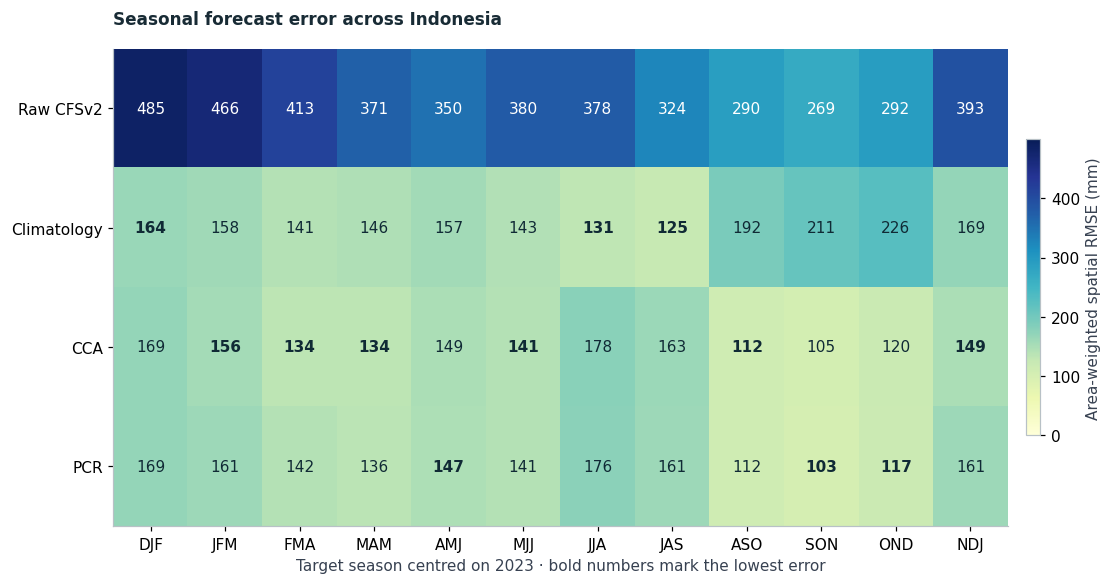

In [5]:
#| label: fig-rmse-overview
#| fig-cap: "Spatial RMSE across the twelve seasons centred on 2023. Lower is better; bold entries identify the lowest unrounded score in each season. All methods use the same country-land cells and weights."
#| fig-alt: "Four methods by twelve seasons: both calibrated forecasts beat the raw model throughout; climatology wins DJF, JJA and JAS."
fig = teach.rmse_overview(main_rmse)
teach.save_figure(fig, artifacts, "rmse-overview")
plt.show()

A calibrated forecast should be compared with both the raw model **and** climatology.
Correcting a large raw bias does not automatically beat a simple observed average.
The following reduction is $100(1-\mathrm{RMSE}_{model}/\mathrm{RMSE}_{climo})$.
It is an RMSE reduction, not a ranked probability skill score or a significance test.

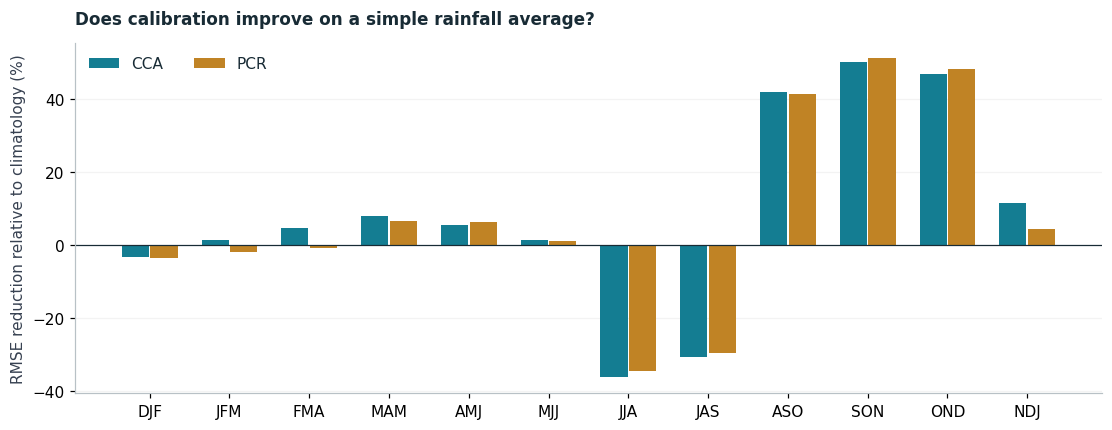

In [6]:
#| label: fig-gain-bars
#| fig-cap: "RMSE reduction relative to the 1991\u20132020 climatology forecast. Positive values mean lower error after calibration; negative values favour climatology."
#| fig-alt: "Paired CCA and PCR bars show seasonal improvements and deterioration against climatology, including losses in DJF, JJA and JAS."
gains = pd.DataFrame({method: 100 * (1 - main_rmse[method] / main_rmse["Climatology"])
                      for method in ("CCA", "PCR")})
gains.to_csv(artifacts / "rmse-reduction-vs-climatology.csv")
fig = teach.gain_bars(gains)
teach.save_figure(fig, artifacts, "gain-bars")
plt.show()

## 5. Walk through OND before looking across every season

OND 2023 was initialized on 1 September and verifies over 1 October–31 December.
Read the five maps on the same rainfall scale. CHIRPS3 is the verification reference;
the other panels are forecasts. More spatial detail is not itself evidence of better
forecasts. The common scale saturates its highest 1% to keep lower totals legible.

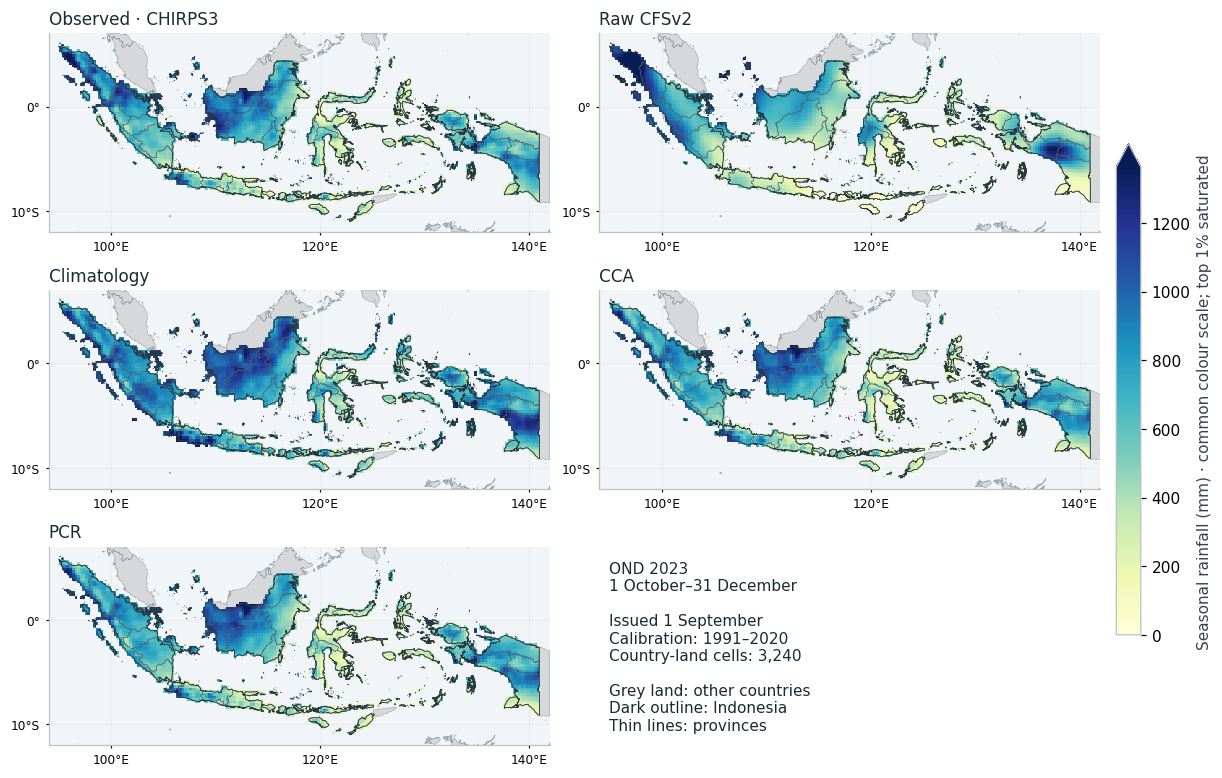

In [7]:
#| label: fig-ond-maps
#| fig-cap: "OND 2023 observed and forecast rainfall on a common scale. Only country-land cells are shaded. The upper 1% is saturated for display; numeric files retain all values. Grey land shows other countries; Indonesia has no boundary fill, with dark country and thin province outlines."
#| fig-alt: "Five Indonesia maps compare observed rainfall with raw CFSv2, climatology, CCA and PCR for October\u2013December 2023."
fig = teach.ond_maps(data)
teach.save_figure(fig, artifacts, "ond-maps")
plt.show()

### Inspect the actual fitting inputs

These NetCDF files are lossless teaching copies of the native CPT text inputs.
They retain the forecast initialization and target coordinates and the missing-value
metadata required by `cptcore`. Predictors and observations have different spatial
grids; their training target dates must match. The observation mean also checks the
OND climatology baseline (within the native text's printed precision).

In [8]:
#| label: ond-inputs
X = load("ond-training-predictor.nc").precipitation
Y = load("ond-training-observations.nc").precipitation
F = load("ond-forecast-predictor.nc").precipitation
np.testing.assert_array_equal(X["T"], Y["T"])
assert X.sizes["T"] == Y.sizes["T"] == 30 and F.sizes["T"] == 1
assert pd.Timestamp(Y.Tf.max().item()) < pd.Timestamp(F.S.min().item())
np.testing.assert_allclose(Y.mean("T").values[mask.values],
    data.forecast_rainfall.sel(season="OND", forecast_variant="climatology_1991_2020").values[mask.values], atol=.01, rtol=0)
print(f"X: {dict(X.sizes)}; Y: {dict(Y.sizes)}; F: {dict(F.sizes)}")
print("Training and forecast dates are separate; climatology check passed.")

X: {'T': 30, 'Y': 41, 'X': 71}; Y: {'T': 30, 'Y': 76, 'X': 192}; F: {'T': 1, 'Y': 41, 'X': 71}
Training and forecast dates are separate; climatology check passed.


### Optional: rerun CCA and PCR in new scratch directories

Keep `RERUN_CPT = False` for the default offline analysis, which needs no PyCPT
or CPT installation. Set it to `True` only in the tested PyCPT fitting environment,
after conda activation sets `CPT_BIN_DIR` for the compatible engine. The supplied
fitting setup is PyCPT 2.10.4, cptio 1.4.0 and CPT 17.8.3. All OND inputs are local;
no IRI Data Library authentication is needed for this refit.

The visible settings below reproduce the fixed-mode design. The scoped reader
handles the audited initialization-date headers without changing forecast numbers.
This refits **OND only**, not all twelve seasons. New logs and outputs go to a unique
`temp/` directory. Returned forecasts are checked against the saved case before export.
The first published execution uses saved results; the optional path is tested separately.

In [9]:
#| label: optional-rerun
RERUN_CPT = False
if RERUN_CPT:
    from cptcore import canonical_correlation_analysis, principal_components_regression
    from pycpt_tutorial.cpt_dates import verified_midnight_reader
    import tempfile
    (root / "temp").mkdir(exist_ok=True)
    work = Path(tempfile.mkdtemp(prefix="ond-tutorial-", dir=root / "temp"))
    settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=5,
                    synchronous_predictors=True, transform_predictand=None, tailoring=None,
                    drymask_threshold=None, skillmask_threshold=None)
    expected_dates = [pd.Timestamp(v).to_pydatetime() for v in np.concatenate([X.S.values, F.S.values])]
    for method, function in (("cca", canonical_correlation_analysis), ("pcr", principal_components_regression)):
        options = dict(settings)
        if method == "cca":
            options.update(y_eof_modes=(3, 3), cca_modes=(2, 2))
        with verified_midnight_reader(function, expected_dates):
            result = function(X, Y, F=F, **options, cpt_kwargs={
                "outputdir": work / method, "log": work / f"{method}.log",
                "project_file": work / f"{method}-commands.txt"})
        forecast = result[1].reindex(X=data.X, Y=data.Y, method="nearest", tolerance=1e-3).where(mask)
        saved = data.forecast_rainfall.sel(season="OND", forecast_variant=f"{method}_1991_2020")
        np.testing.assert_allclose(forecast.deterministic.isel(T=0), saved, atol=.01, rtol=0, equal_nan=True)
        save_netcdf(forecast, work / f"{method}-forecast.nc", overwrite=False)
    print(f"CCA/PCR reruns match saved OND forecasts; new outputs: {work}")
else:
    print("Calibration rerun skipped; all comparisons use the hash-verified saved results.")

Calibration rerun skipped; all comparisons use the hash-verified saved results.


## 6. Inspect geographic differences across all twelve seasons

Subtract each calibrated absolute error from climatology's absolute error at the
same cell. Positive values mean calibration helped there; negative values mean
climatology did better. A lower national RMSE can coexist with local deterioration.
The atlas shows both models for every season, rather than selecting only favourable maps.
Colours saturate beyond ±300 mm; downloadable numeric fields retain all values.

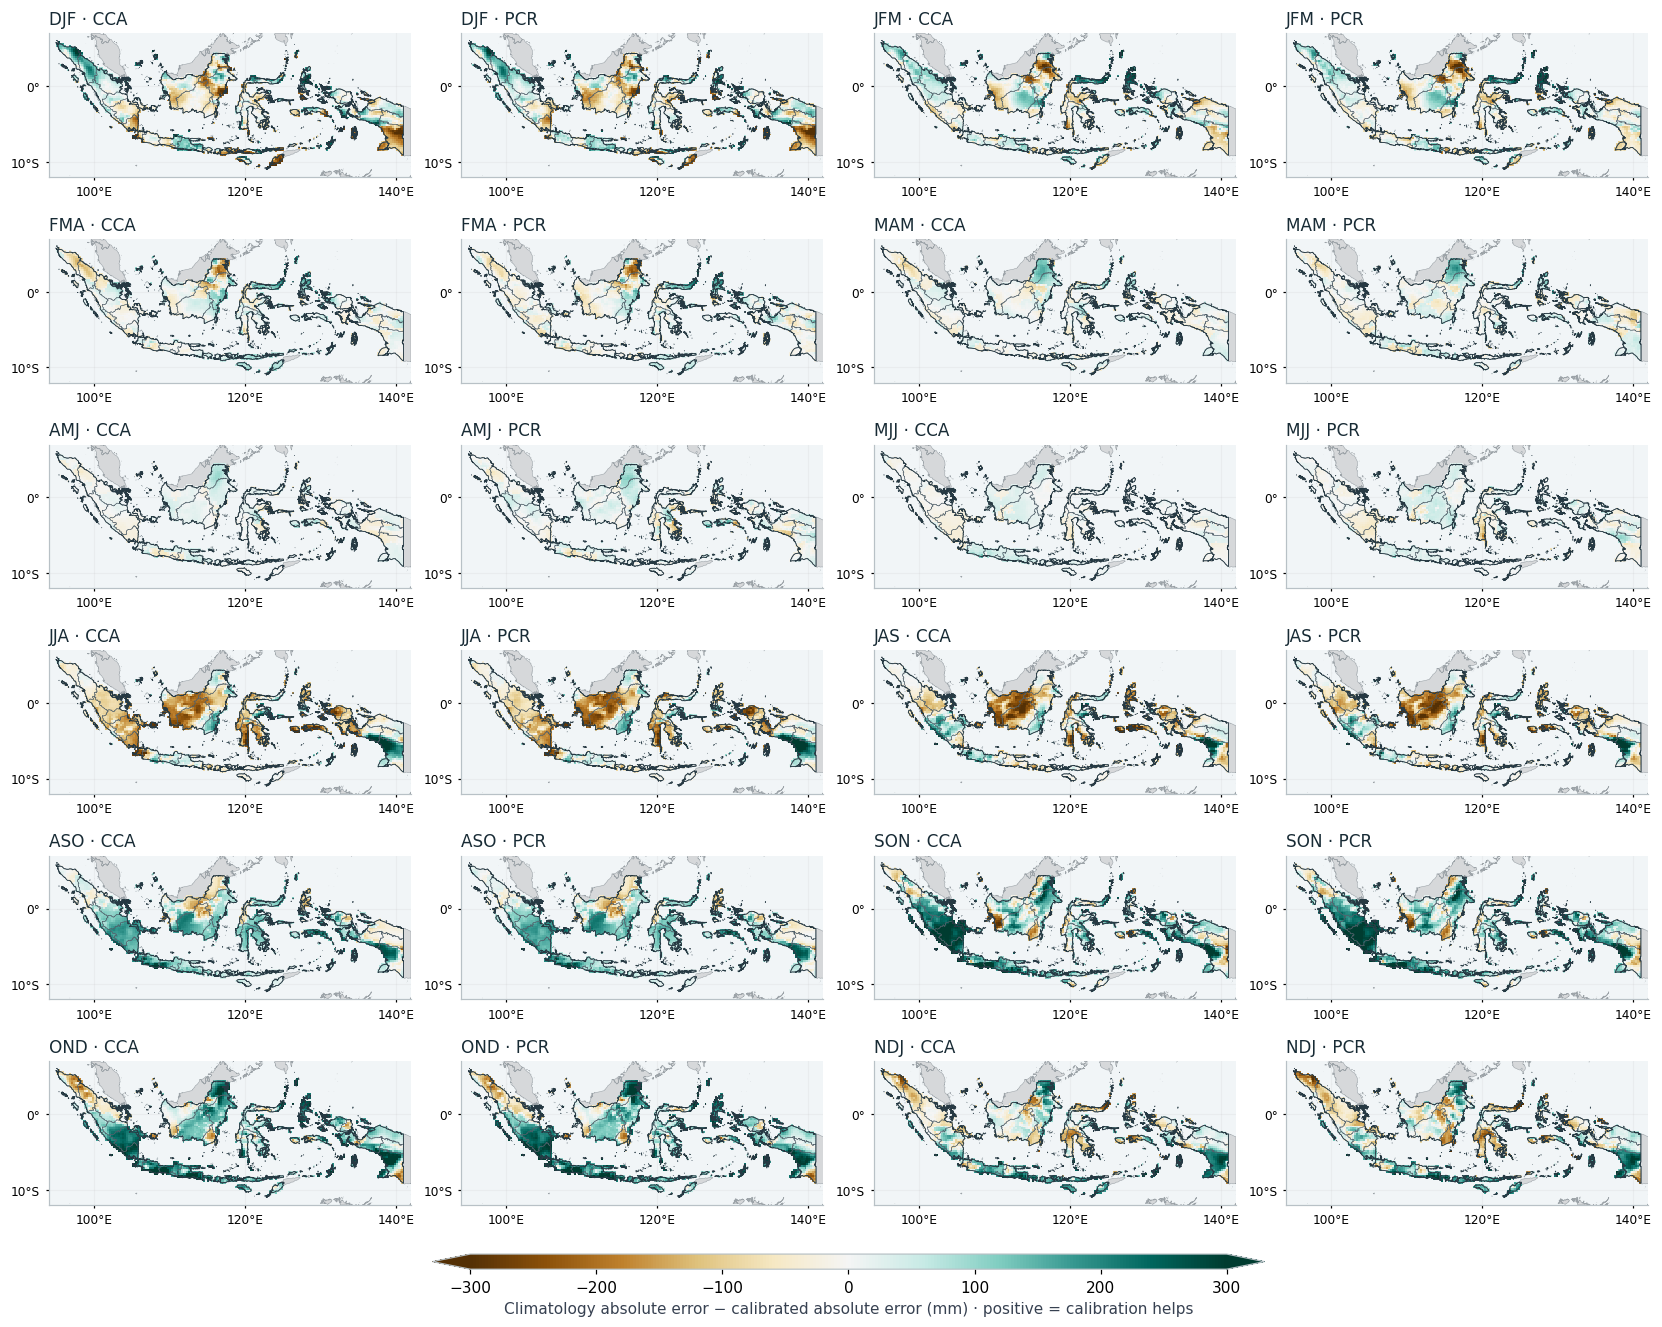

In [10]:
#| label: fig-error-atlas
#| fig-cap: "Local absolute-error reduction relative to climatology for CCA and PCR in every season. Green means calibration helps, brown means it worsens the local forecast; colours saturate beyond \u00b1300 mm. Grey land shows other countries; Indonesia has no boundary fill, with dark country and thin province outlines."
#| fig-alt: "Twenty-four maps show geographically mixed CCA and PCR error reductions across all twelve seasons, including local failures."
reference_error = abs(error.sel(forecast_variant="climatology_1991_2020"))
local_gain = reference_error - abs(error.sel(forecast_variant=["cca_1991_2020", "pcr_1991_2020"]))
local_gain.attrs.update(units="mm", long_name="Absolute-error reduction relative to climatology")
save_netcdf(local_gain.rename("absolute_error_reduction"), artifacts / "local-error-reduction-2023.nc",
    metadata={"units": "mm", "positive_means": "Calibration has smaller absolute error than climatology"}, overwrite=True)
fig = teach.error_atlas(data)
teach.save_figure(fig, artifacts, "error-atlas")
plt.show()

## 7. Compare provinces on the existing forecast grid

The supplied file contains 38 provinces. We define the regions from these boundaries
before inspecting their forecast errors, and keep every province. Analysis uses
the **unsimplified** polygons, not the display GeoJSON. A native 0.05° pixel is
assigned only when its centre lies inside exactly one province; gaps or overlaps
remain separate categories. Cosine-latitude weights are the same as in the original
country aggregation. See the [weighting example](https://docs.xarray.dev/en/stable/examples/area_weighted_temperature.html)
and [point-containment definition](https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html).

These are **province-weighted scores of the saved 0.25° cell errors**. Where a
coarse cell crosses a province border, provinces share that cell's forecast and
observation error, but receive different native-pixel weight shares. This does
not reconstruct province-only rainfall inside that cell or create finer forecast
information. Small provinces need particular care. The boundary snapshot is not
a certification of current or historical official administrative limits.

In [11]:
#| label: regional-setup
region_dir = data_dir / 'regions'
region_provenance = json.loads((region_dir / 'provenance.json').read_text())
for name, record in region_provenance['outputs'].items():
    assert hashlib.sha256((region_dir / name).read_bytes()).hexdigest() == record['sha256'], name
def load_region(name):
    with xr.open_dataset(region_dir / name) as source:
        return source.load()
regions = load_region('province-weights.nc')
native_membership = load_region('native-membership.nc')
regional_annual = load_region('province-context-annual.nc')
regional_pooled = load_region('province-context-pooled.nc')
province_names = regions.region.values[regions.is_province.values.astype(bool)].tolist()
assert len(province_names) == 38
np.testing.assert_allclose(regions.region_weight.sum('region'), data.evaluation_weight, atol=1e-12, rtol=0)
region_mass = regions.region_weight.sum(('Y','X'))
region_fraction = region_mass / region_mass.sum()
unassigned_fraction = region_provenance['unassigned_weight_fraction']
print(f"All 38 provinces retained; {100*unassigned_fraction:.2f}% of country weight unassigned; "
      f"{region_provenance['overlap_points']} overlapping native points. No nearest-province assignment.")

All 38 provinces retained; 1.31% of country weight unassigned; 0 overlapping native points. No nearest-province assignment.


In [12]:
#| label: tbl-province-support
support_table = pd.DataFrame({
    'Region': regions.region.values,
    'Country weight (%)': 100*region_fraction.values,
    'Contributing coarse cells': regions.contributing_cells.values,
    'Largest single-cell share (%)': 100*regions.largest_cell_weight_fraction.values,
})
support_table.to_csv(artifacts / 'province-support.csv', index=False)
display(HTML(support_table.round(2).to_html(index=False, classes='table table-sm', border=0)))

Region,Country weight (%),Contributing coarse cells,Largest single-cell share (%)
Aceh,3.00,102,1.37
Bali,0.28,16,14.53
Banten,0.49,22,8.36
Bengkulu,1.05,44,3.90
Daerah Khusus Ibukota Jakarta,0.03,3,63.16
Daerah Istimewa Yogyakarta,0.17,9,24.27
Gorontalo,0.63,26,6.51
Jambi,2.60,82,1.58
Jawa Barat,1.97,66,2.07
Jawa Tengah,1.80,65,2.26


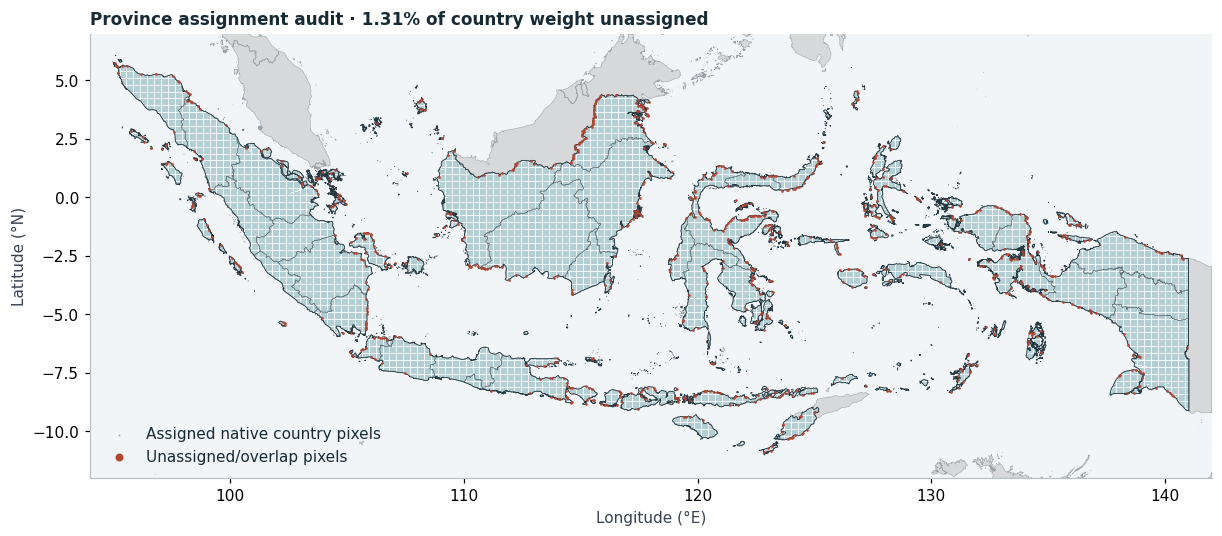

In [13]:
#| label: fig-province-support
#| fig-cap: "Native country-pixel assignment to the supplied provinces. Red points remain an explicit residual category; the original national footprint is preserved."
#| fig-alt: "Indonesia map shows assigned native pixels in blue and unassigned pixels in red, with country and province boundaries."
fig = teach.province_support_map(native_membership, unassigned_fraction)
teach.save_figure(fig, artifacts, 'province-support-map')
plt.show()

Normalize the weight **within each region**, then calculate the same spatial MSE,
RMSE, MAE and bias as before. For regional weight fraction $a_r$, national MSE
must equal $\sum_r a_r\,\mathrm{MSE}_r$, including the residual category.
National RMSE is the square root of that result, not an average of province RMSEs.
The following code checks the identity and the archived regional scores.

In [14]:
#| label: regional-scores
regional_weights = regions.region_weight / region_mass
regional = xr.Dataset({
    'mse': (error.fillna(0)**2 * regional_weights).sum(('Y','X')),
    'mae': (abs(error.fillna(0)) * regional_weights).sum(('Y','X')),
    'bias': (error.fillna(0) * regional_weights).sum(('Y','X')),
})
regional['rmse'] = np.sqrt(regional.mse)
for variable in regional:
    regional[variable].attrs['units'] = 'mm2' if variable == 'mse' else 'mm'
for variable in ('rmse','mae','bias'):
    combined = np.sqrt((regional.mse*region_fraction).sum('region')) if variable=='rmse' else (regional[variable]*region_fraction).sum('region')
    np.testing.assert_allclose(combined, scores[variable], atol=1e-8, rtol=0)
for season in teach.SEASONS:
    selected = regional_annual.sel(season=season, season_year=int(data.source_season_year.sel(season=season)))
    for variable in regional:
        xr.testing.assert_allclose(regional[variable].sel(season=season, drop=True).reset_coords(drop=True),
                                   selected[variable].reset_coords(drop=True))
save_netcdf(regional, artifacts / 'province-verification-2023.nc', overwrite=True,
            metadata={'scope':'Province-weighted views of existing 0.25degree errors; includes unassigned residual',
                      'calendar':'Target midpoints2023, NDJ source ending-year2024'})
regional.to_dataframe().reset_index().to_csv(artifacts / 'province-metrics-2023.csv', index=False)
regional_annual.to_dataframe().reset_index().to_csv(artifacts / 'province-metrics-context-annual.csv', index=False)
regional_pooled.to_dataframe().reset_index().to_csv(artifacts / 'province-metrics-context-pooled.csv', index=False)
print('Province plus residual MSE, MAE and bias reproduce the national scores.')

Province plus residual MSE, MAE and bias reproduce the national scores.


In [15]:
#| label: tbl-province-ond
ond_province_rmse = regional.rmse.sel(season='OND', forecast_variant=main_variants).transpose('region','forecast_variant').to_pandas().rename(columns=teach.LABELS)
ond_province_rmse.to_csv(artifacts / 'province-ond-2023-rmse.csv')
display(HTML(ond_province_rmse.round(2).to_html(classes='table table-sm', border=0)))

forecast_variant,Raw CFSv2,Climatology,CCA,PCR
region,,,,
Aceh,496.40,239.55,287.95,285.18
Bali,131.79,374.22,127.44,114.07
Banten,472.04,338.91,143.49,77.23
Bengkulu,329.06,408.35,165.10,119.89
Daerah Khusus Ibukota Jakarta,102.33,222.08,63.52,45.95
Daerah Istimewa Yogyakarta,127.20,292.46,106.94,117.33
Gorontalo,141.78,45.74,119.68,123.46
Jambi,273.79,239.76,93.74,86.64
Jawa Barat,297.05,380.67,106.95,78.61


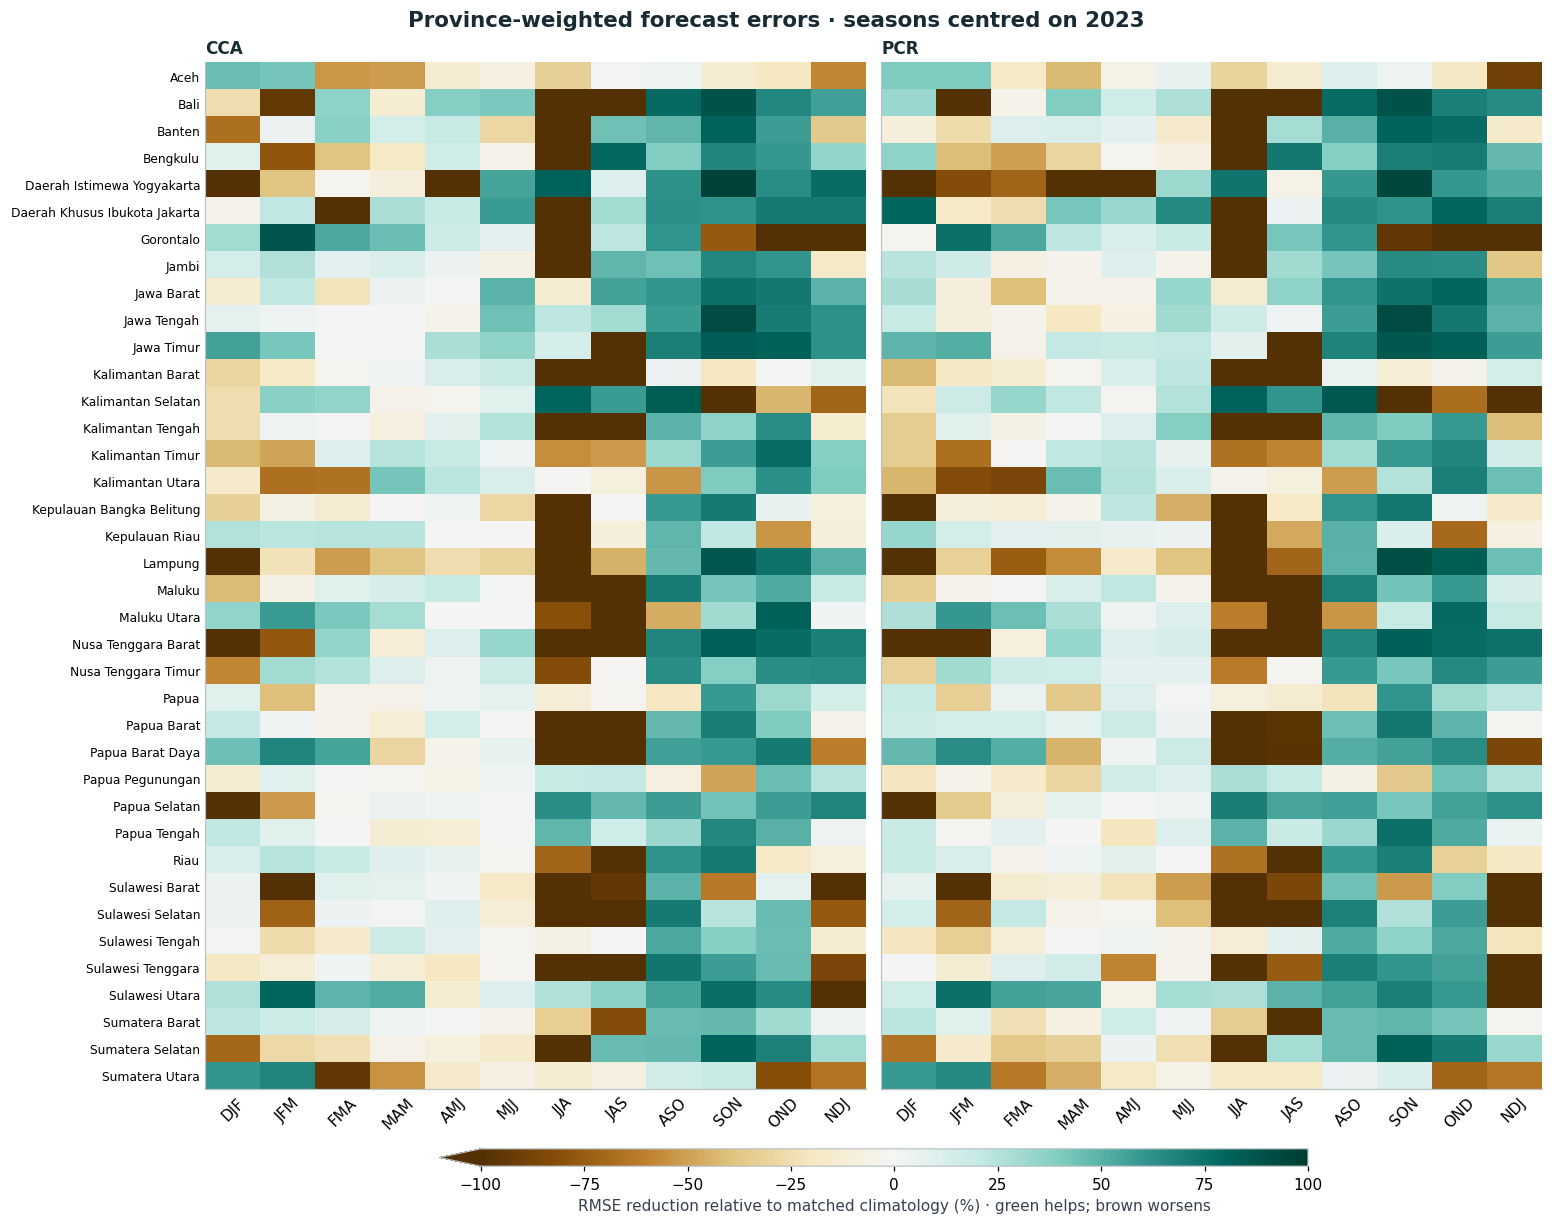

In [16]:
#| label: fig-province-gains
#| fig-cap: "RMSE reductions for CCA and PCR relative to 1991\u20132020 climatology in every supplied province. Green means smaller error, brown larger error. Values below \u2212100% saturate; files retain all values. These are weights on existing 0.25\u00b0 errors, not finer province rainfall reconstructions."
#| fig-alt: "Two heatmaps compare CCA and PCR against climatology across all 38 provinces and 12 target windows centred on 2023."
fig = teach.province_heatmap(regional.sel(region=province_names), 'Province-weighted forecast errors · seasons centred on 2023')
teach.save_figure(fig, artifacts, 'province-gains-2023')
plt.show()

Repeat the comparison using all four original **ending-year 2021–2024** labels.
Pool annual MSE before taking its square root; each year has equal weight.
This context includes2023 and is not independent confirmation of it. It does,
however, expose patterns that change when the other archived years are included.
Seven forecast variants, both training periods, raw and matched climatologies
remain in the downloadable annual and pooled tables.

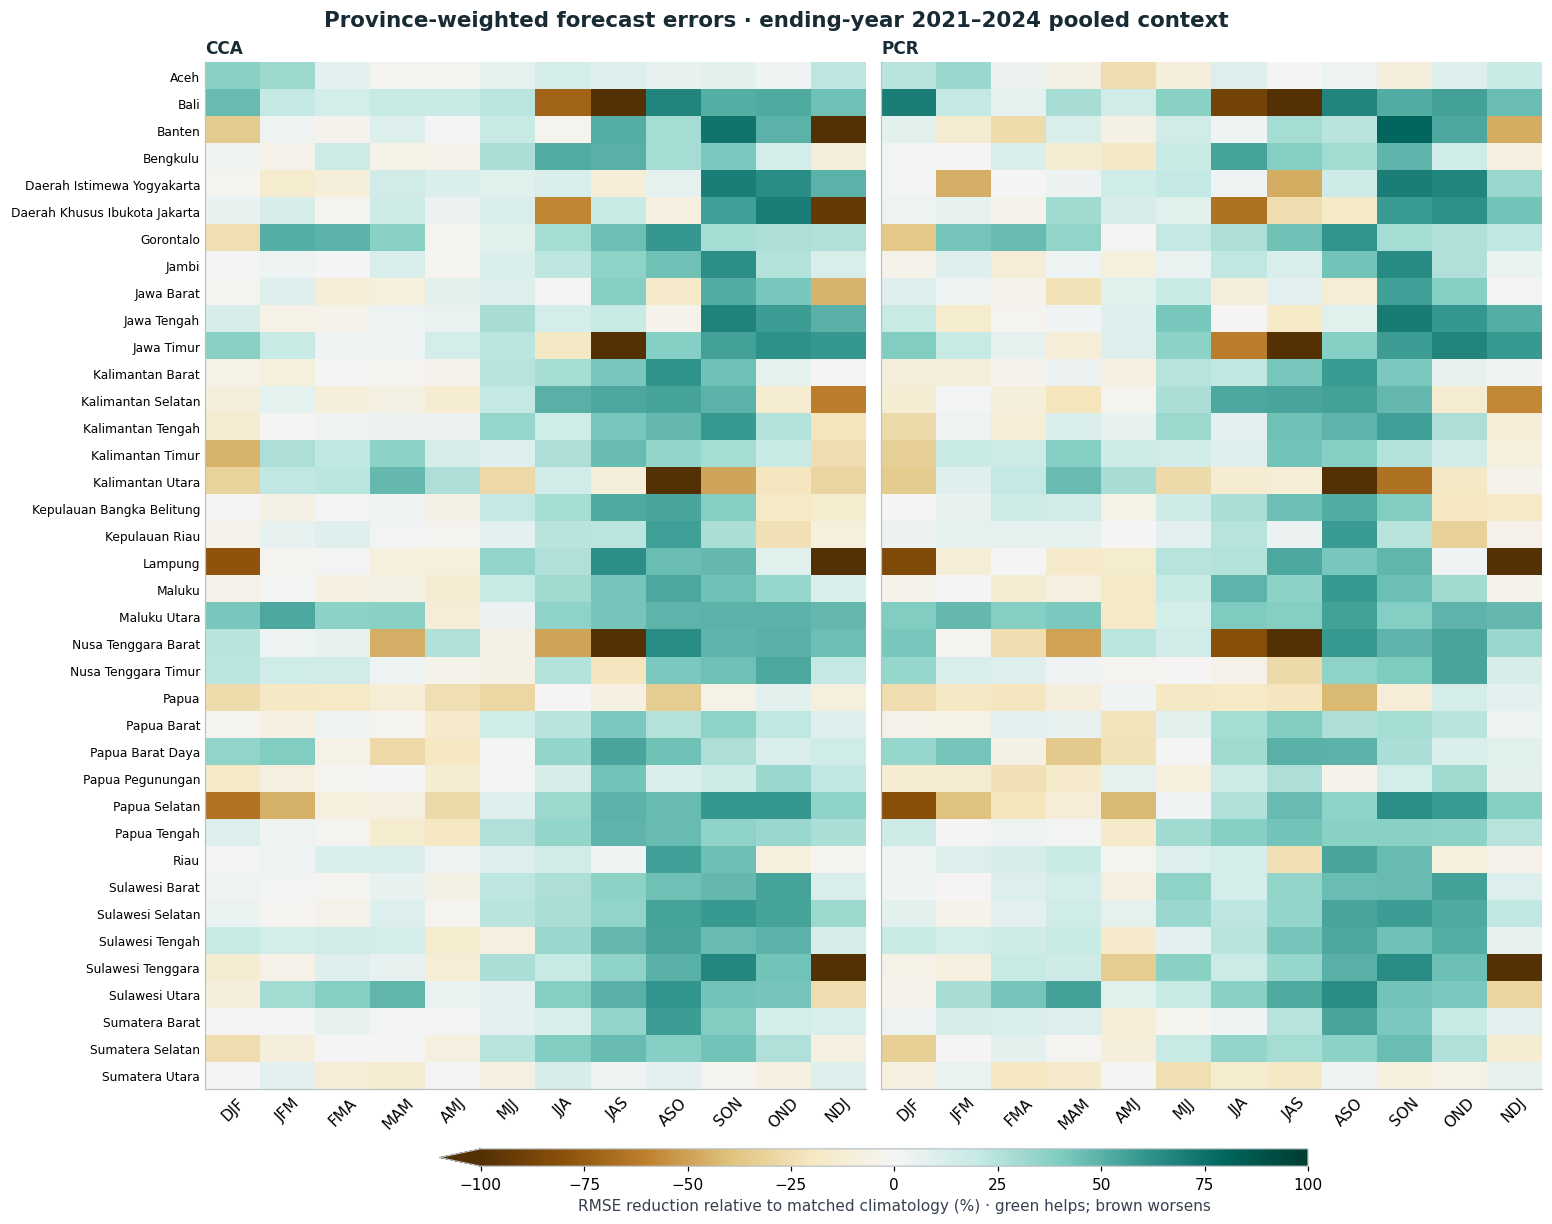

In [17]:
#| label: fig-province-context
#| fig-cap: "The same provinces and fixed colour scale using pooled ending-year 2021\u20132024 errors. This includes2023, not an independent validation set. Equal-year MSE is averaged before the square root."
#| fig-alt: "Two heatmaps show CCA and PCR RMSE reductions relative to matched climatology for all 38 provinces in the original four-year context."
np.testing.assert_allclose(regional_pooled.rmse, np.sqrt(regional_annual.mse.mean('season_year')), atol=1e-8, rtol=0)
fig = teach.province_heatmap(regional_pooled.sel(region=province_names), 'Province-weighted forecast errors · ending-year 2021–2024 pooled context')
teach.save_figure(fig, artifacts, 'province-gains-context')
plt.show()

In [18]:
(root / 'docs/_includes').mkdir(exist_ok=True)
#| label: regional-findings
def province_win_counts(ds):
    chosen = ds.sel(region=province_names)
    base = chosen.rmse.sel(forecast_variant='climatology_1991_2020')
    return {m: (chosen.rmse.sel(forecast_variant=f'{m.lower()}_1991_2020') < base).sum('region').to_pandas().reindex(teach.SEASONS) for m in ('CCA','PCR')}
counts23 = province_win_counts(regional)
counts4 = province_win_counts(regional_pooled)
province_counts = pd.DataFrame({'2023 CCA':counts23['CCA'], '2023 PCR':counts23['PCR'],
                                'Four-year CCA':counts4['CCA'], 'Four-year PCR':counts4['PCR']})
province_counts.index.name = 'Season'
province_counts.to_csv(artifacts / 'province-improvement-counts.csv')
display(HTML(province_counts.to_html(classes='table table-sm', border=0)))
regional_summary = {'provinces':38, 'unassigned_weight_percent':100*unassigned_fraction,
                   'native_points':region_provenance['native_points'], 'unassigned_points':region_provenance['unassigned_points'],
                   'overlap_points':region_provenance['overlap_points'], 'province_counts':province_counts.to_dict(),
                   'scope':'Descriptive province-weighted coarse-cell errors; overlapping seasons and four years do not establish operational skill'}
(artifacts / 'regional-findings.json').write_text(json.dumps(regional_summary, indent=2)+'\n')
regional_text = (f"For OND 2023, CCA has lower RMSE than climatology in **{int(counts23['CCA']['OND'])} of 38 provinces**, "
                 f"and PCR in **{int(counts23['PCR']['OND'])} of 38**. For JJA 2023, the corresponding counts are "
                 f"**{int(counts23['CCA']['JJA'])}** and **{int(counts23['PCR']['JJA'])}**, despite the national comparison favouring climatology. "
                 f"In the four-year pooled JJA context, they become **{int(counts4['CCA']['JJA'])}** and **{int(counts4['PCR']['JJA'])}**. "
                 "Those changes show why one year should not be turned into a province-specific forecast recommendation.")
small = support_table[support_table['Region'].isin(province_names)].sort_values('Contributing coarse cells').iloc[0]
regional_text += (f" The smallest support is **{small['Region']}**, with **{int(small['Contributing coarse cells'])} coarse cells**; "
                  f"its largest single cell carries **{small['Largest single-cell share (%)']:.1f}%** of its weight. These are support diagnostics, not independent sample counts.")
(root / 'docs/_includes/regional-findings.qmd').write_text(regional_text+'\n')
coverage_text = (f"The province polygons contain **{100*(1-unassigned_fraction):.2f}%** of the original country weight. "
                 f"The remaining **{100*unassigned_fraction:.2f}%** ({region_provenance['unassigned_points']:,} native country pixels) "
                 "is retained as an explicit unassigned category. There are no multiply assigned native pixels. "
                 "Province plus residual errors recombine to the unchanged national scores.")
(root / 'docs/_includes/regional-coverage.qmd').write_text(coverage_text+'\n')
print('Regional findings and all-season count table exported; counts are descriptive, not independent samples.')

,2023 CCA,2023 PCR,Four-year CCA,Four-year PCR
Season,,,,
DJF,19,20,17,21
JFM,21,15,23,23
FMA,22,14,22,22
MAM,20,20,22,24
AMJ,25,25,13,15
MJJ,22,25,32,30
JJA,8,8,32,28
JAS,17,14,31,27
ASO,34,34,33,33


Regional findings and all-season count table exported; counts are descriptive, not independent samples.


## 8. Keep the training-period sensitivity visible

Compare the same forecast windows using 1983–2010 (28 training seasons) and
1991–2020 (30). The common older start avoids missing 1981 initializations for
the cross-year seasons in the original all-season design. This changes training
years, sample count, EOF bases and fitted relationships together. It is not a
controlled estimate of the effect of sample count alone, and does not justify
selecting whichever period happens to win a particular 2023 season.

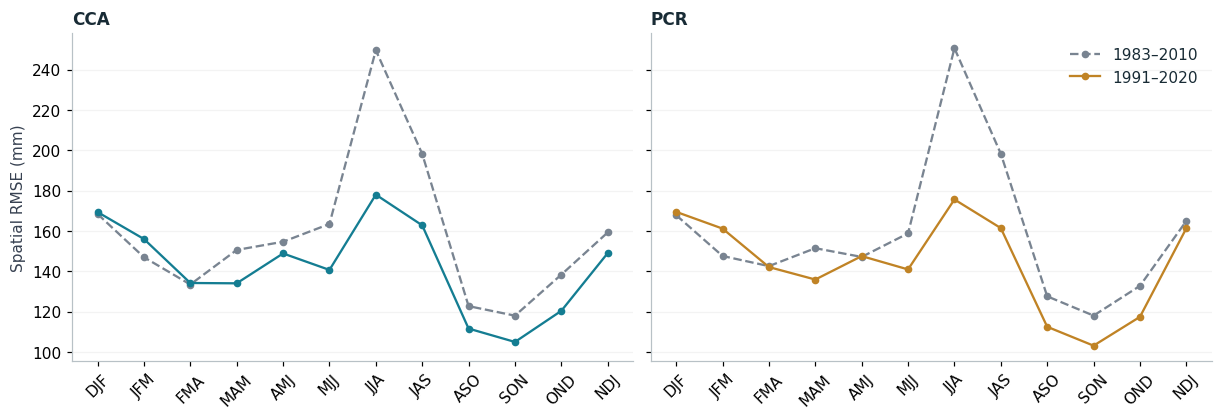

In [19]:
#| label: fig-training-sensitivity
#| fig-cap: "The same target windows with two fixed training intervals. Both sample count and training years change; this is a sensitivity comparison, not a period-selection rule."
#| fig-alt: "Two line charts compare CCA and PCR spatial RMSE under1983\u20132010 and1991\u20132020 training."
sensitivity = rmse[[f"{m}_{p}" for m in ("climatology", "cca", "pcr") for p in ("1983_2010", "1991_2020")]]
sensitivity.to_csv(artifacts / "training-period-sensitivity.csv")
fig = teach.sensitivity_plot(rmse)
teach.save_figure(fig, artifacts, "training-sensitivity")
plt.show()

In [20]:
#| label: tbl-training-sensitivity
display(HTML(sensitivity.round(2).to_html(classes="table table-sm", border=0)))

forecast_variant,climatology_1983_2010,climatology_1991_2020,cca_1983_2010,cca_1991_2020,pcr_1983_2010,pcr_1991_2020
season,,,,,,
DJF,170.04,163.87,168.39,169.33,167.79,169.44
JFM,158.72,158.38,146.94,155.97,147.55,161.14
FMA,146.01,140.80,133.40,134.15,142.52,142.06
MAM,155.61,145.54,150.55,133.99,151.42,135.87
AMJ,163.76,157.28,154.61,148.81,147.08,147.49
MJJ,146.70,142.65,163.43,140.64,158.76,140.88
JJA,133.33,130.69,249.61,177.98,250.63,175.59
JAS,137.94,124.70,198.21,162.76,198.28,161.39
ASO,214.27,192.06,122.68,111.54,127.54,112.43


## 9. Put a single year in a broader context

The original benchmark covers **ending-year labels 2021–2024**. Retain that
convention here: its NDJ windows are November 2020–January 2021 through
November 2023–January 2024. This is not four complete midpoint-calendar-year
collections. The 2023-centred selection above uses the final NDJ window.

Pooled RMSE takes the square root after averaging squared errors across years
and locations; it is not the arithmetic mean of annual RMSE. The assertions below
check that identity with equal annual coverage. Four years, overlapping seasons
and spatially correlated cells do not establish general operational forecast skill.

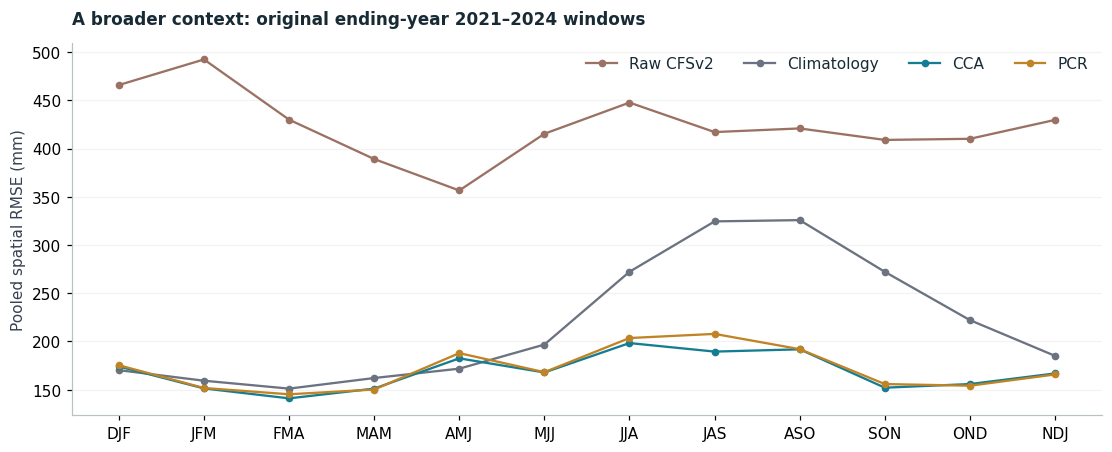

In [21]:
#| label: fig-multiyear-context
#| fig-cap: "Pooled spatial errors in the original ending-year 2021\u20132024 benchmark. These labels differ from the midpoint-year selection used for the main 2023 case."
#| fig-alt: "Four lines compare pooled forecast errors over twelve seasons, with climatology still competitive in some windows."
pooled = context.pooled_rmse.sel(evaluation_set="all_four_years")
np.testing.assert_allclose(pooled, np.sqrt((context.rmse ** 2).mean("season_year")), atol=1e-8, rtol=0)
context_table = pooled.to_pandas().reindex(teach.SEASONS)[main_variants].rename(columns=teach.LABELS)
context_table.to_csv(artifacts / "context-ending-years-2021-2024.csv")
fig = teach.context_plot(context_table)
teach.save_figure(fig, artifacts, "multiyear-context")
plt.show()

## 10. Export findings for the story and check provenance

The story includes the following generated text. Its numerical claims come from
the same scores used in the figures, so a revised execution cannot silently leave
manually copied numbers in the narrative. The final hash check confirms that
none of the packaged inputs changed during execution.

In [22]:
#| label: generated-findings
wins = {m: int((main_rmse[m] < main_rmse["Climatology"]).sum()) for m in ("CCA", "PCR")}
raw_wins = {m: int((main_rmse[m] < main_rmse["Raw CFSv2"]).sum()) for m in ("CCA", "PCR")}
best = main_rmse.idxmin(axis=1)
climo_best = best.index[best == "Climatology"].tolist()
ond = main_rmse.loc["OND"]
period_wins = {m: int((rmse[f"{m}_1991_2020"] < rmse[f"{m}_1983_2010"]).sum()) for m in ("cca", "pcr")}
summary = {"main_year_convention": "Midpoints in2023; NDJ source ending-year2024", "main_training_period": "1991–2020",
           "calibration_beats_climatology_seasons": wins, "calibration_beats_raw_seasons": raw_wins,
           "lowest_rmse_method_by_season": best.to_dict(), "ond_rmse_mm": ond.to_dict(),
           "recent_training_lower_rmse_seasons": period_wins,
           "original_context_pooled_rmse_mm": context_table.to_dict(), "data_input_hashes": provenance["outputs"]}
(artifacts / "findings.json").write_text(json.dumps(summary, indent=2) + "\n")
text = (f"Across the twelve windows centred on 2023, CCA reduced spatial RMSE relative to the raw model in **{raw_wins['CCA']} seasons**; "
        f"PCR did so in **{raw_wins['PCR']}**. Against the more demanding climatology baseline, CCA improved in **{wins['CCA']} of 12** "
        f"and PCR in **{wins['PCR']} of 12**.\n\n"
        + (f"Climatology had the lowest RMSE of all four methods in **{', '.join(climo_best)}**. " if climo_best else "Climatology was not the lowest-RMSE method in this particular set of windows. ")
        + "These are descriptive comparisons for these forecast windows, not a test of statistical significance.")
includes = root / "docs/_includes"
includes.mkdir(exist_ok=True)
(includes / "seasonal-findings.qmd").write_text(text + "\n")
ond_text = (f"For OND, spatial RMSE was **{ond['Raw CFSv2']:.1f} mm** for the raw model and **{ond['Climatology']:.1f} mm** for climatology, "
            f"compared with **{ond['CCA']:.1f} mm** for CCA and **{ond['PCR']:.1f} mm** for PCR. "
            "Those numbers describe errors over country-land cells; they are not national-mean rainfall totals.")
(includes / "ond-findings.qmd").write_text(ond_text + "\n")
teach.verify_bundle(data_dir)
display(HTML(f"<p><strong>Input integrity passed.</strong> CCA beats climatology in {wins['CCA']}/12 seasons; PCR in {wins['PCR']}/12.</p>"))

## What this notebook does not establish

The twelve windows overlap; they are not twelve independent annual samples. The
reference observations and archived model fields use current data vintages, not
an exact reconstruction of everything available when forecasts were issued.
The CFSv2 archive appends operational forecasts from April 2011; continuity does
not establish homogeneity. Physical EOF/CCA-pattern review, independent station
checks, longer validation and predefined regional diagnostics remain follow-up work.

Native probabilities are deliberately outside this first comparison. Their category
reference dates differ from some training periods; zero-bounded outputs do not always
equal their unbounded locations. Some high-level notebook probability scores are
in-sample, and flexible exceedance calculations differ from native CPT17. Read the
book's methods and limitations page before using those outputs.

**Sources:** [IRI CPT teaching reference](https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/cpt.html),
[official notebook collection](https://github.com/iri-pycpt/notebooks),
and the project's frozen case, methodology audit and official-notebook comparison.

## References {.unnumbered .reference-section}

1. IRI. *Guide to PyCPT 2 for Seasonal Climate Forecasts* (Jupyter Book, 2 September 2023 build): The Climate Predictability Tool (CPT). <https://iri.columbia.edu/~awr/pycpt/seasonal-jupyterbook/html_2sep2023/cpt.html>
2. IRI. *PyCPT example notebooks*. GitHub repository iri-pycpt/notebooks. <https://github.com/iri-pycpt/notebooks>
3. xarray. *Compare weighted and unweighted mean temperature* (example gallery). <https://docs.xarray.dev/en/stable/examples/area_weighted_temperature.html>
4. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
5. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
7. Kirtman, B., Min, D., Infanti, J., et al. (2014). The North American Multimodel Ensemble: Phase-1 seasonal-to-interannual prediction; Phase-2 toward developing intraseasonal prediction. *Bulletin of the American Meteorological Society*, 95(4), 585-601. <https://doi.org/10.1175/BAMS-D-12-00050.1>
8. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
9. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>